> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage4_agent_and_mcp_execution_ko.ipynb`)](../ko/stage4_agent_and_mcp_execution_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Starter README](../../README.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open the Starter demo](https://agentic-ontology-starter-115847445822.asia-northeast3.run.app/)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → **[▶ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb)** → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 4. [Build Agent & Answer] Resource-Connected 3 Domain Business Tools, Slot Validation & 2-Pass AI FDE (`Gate G2-W`) Execution
## Step 4.1 3 Domain Business Tools Catalog (`get_tool_catalog`) Setup · Step 4.2 Deterministic Math & `Gate G2-W` Answering

Stage 4 implements **Phase 6 (Agent & Tools Setup)** and **Phase 7 (Grounded Answering)**. In Starter Pack v2.2.0, heavy internal ontology builder tools are abstracted away, exposing only the **3 Ready-to-Use Resource-Connected Domain Business Tools (`mcp_lookup_customer_profile`, `mcp_calculate_penalty_rule`, `mcp_query_graph_and_wiki`)**. To prevent LLM math errors or entity hallucinations, we combine **(1) Live BigQuery Catalog Slot Resolution (`resolve_params`)**, **(2) `DomainMcpServer` executing deterministic SQL and parameterized ISO GQL across both `engine='bigquery'` (default) and `engine='spanner'`**, and **(3) the `Gate G2-W` audited 2-Pass Gemini (`gemini-4-argon`) Reasoning Engine (`AiFdeAgentEngine`)**.

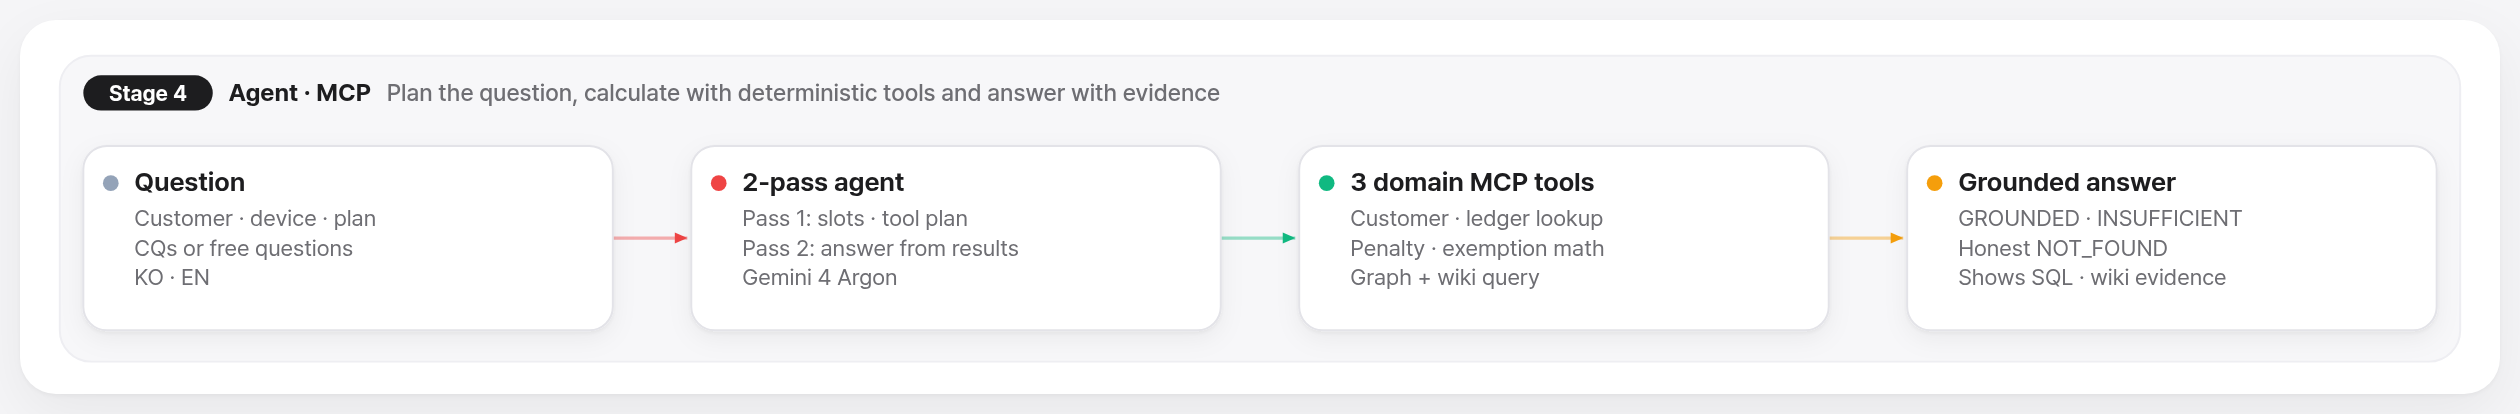


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: Resource-Connected 3 Domain Business Tools & Agent Setup] Code Exposure Boundary, 3 Domain Tools Catalog & `stage4_resource_check`


In [ ]:
H.draw_agent_architecture()
manifest = server.get_resource_manifest()
H.show(pd.DataFrame(manifest["code_exposure_boundary"]["exposed_starter_layer"])[["file", "category", "role_ko" if H.LANG == "ko" else "role_en"]])
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_source", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("stage4_resource_check", {"steps": ["step_4_1", "step_4_2"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: Catalog-Validated Slot Resolution (`resolve_params`)] Extracting Parameters & Stripping Unregistered Entities


In [ ]:
sample_queries = [
    "If customer CUST_DEMO_001 downgrades to 5G Light (37,000 KRW) on day 120, what is the penalty?",
    "When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the subsidy and net price?",
    "What is the penalty if customer CUST_NOT_EXIST_999 switches to a 99,000 KRW plan on a QuantumFold 99 device?",
    "I just activated my line—what is the penalty if I downgrade to the 37,000 KRW plan?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


### 3. [Phase 6c: Direct Execution of 3 Runtime Domain MCP Tools] Customer Profile, Penalty/24M TCO Math, Graph Traversal (`executed_gql` + Bound Variables) & 180-Day Penalty Curve


In [ ]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       "CUST_DEMO_001 Prorated Penalty Curve Across Elapsed Days 30..200 (180-Day Exemption Threshold)",
       vline=180, vline_label="180d threshold")


In [ ]:
H.md("#### BigQuery resources per MCP call (`bq_jobs`: job_id, rows, elapsed_ms)")
H.show(pd.DataFrame([{"tool": r["tool"], "job_id": j["job_id"], "engine": j["engine"], "status": j["status"], "rows": j["rows"], "elapsed_ms": j["elapsed_ms"]}
                     for r in (r_prof, r_pen, r_gql) for j in r.get("bq_jobs", [])]))


### 4. [Phase 6d: Dual-Engine Domain Tool Runtime Execution (`engine="bigquery"` vs. `engine="spanner"`)] Cloud Spanner Graph Execution Parity & Latency Comparison


In [ ]:
df_mcp_eng = H.compare_mcp_engines(server)
H.show(df_mcp_eng)
H.grouped_bar(df_mcp_eng, "mcp_tool", ["bigquery_ms", "spanner_ms"],
              "Runtime Domain MCP Tools — BigQuery (Default) vs. Cloud Spanner (100 PU) Latency Comparison (ms)",
              fmt="{:,.1f}", ylabel="Latency (ms)")


### 5. [Phase 7: End-to-End 2-Pass Agent Answering] Golden CQs (`GROUNDED`) & Boundary Guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)


In [ ]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the public subsidy, retail additional subsidy cap, total subsidy, and net purchase price?"),
    ("CQ-02 (120d Prorated Penalty)", "If customer CUST_DEMO_001 downgrades to the 37,000 KRW monthly plan (5G Lite 37) on day 120 after activation, what is the prorated difference penalty?"),
    ("CQ-03 (Welfare Exemption)", "Is customer CUST_DEMO_002 (registered under National Merit Welfare) exempt from penalty charges when downgrading to a lower plan on day 95?"),
    ("BC-PARAM (Missing Customer/Device)", "I am a newly activated subscriber—what is the penalty if I downgrade to the 5G Lite 37 plan right now?"),
    ("BC-NOTFOUND (Unknown Entity)", "Please calculate the penalty when customer CUST_NOT_EXIST_999 changes plans with a QuantumFold 99 device."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append({**H.agent_row(res, qid.split()[0]), "prompt_tokens": res["llm_telemetry"]["prompt_tokens"],
                 "completion_tokens": res["llm_telemetry"]["candidates_tokens"]})
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              "Gemini 2-Pass LLM Inference vs. BigQuery SQL/GQL Latency by Scenario (ms)")


### 6. Wiki Agent vs BQG Agent, and usage reporting

The method separates the two agents by where they get evidence.

| Item | Wiki Agent (method) | BQG Agent (method) |
| :--- | :--- | :--- |
| Evidence | Ontology wiki files on GCS | BigQuery Property Graph |
| Steps | Read the wiki index on GCS → Flash selects entity/concept files → read those files (+1 hop of relations) → Flash answers from file content only | Slot extraction → parameterized GQL over the property graph → calculation in code → answer |
| BigQuery and graph | Not used | Used |
| Usage reported | Tokens per call (Vertex `usageMetadata`: prompt, completion, thinking) and latency per step | Same, plus BigQuery job ID, rows and elapsed ms per query |

A separate Wiki Agent checks whether Stage 2 output alone, without the physical graph, can answer rule and formula CQs.

**Starter implementation (differs from the method)**
- The starter has no GCS Wiki Agent. Its GCS ontology is `gs://seanjung-poc-starter-ontology/ontology/{entities.md, concepts.md, rules.md, summary.md, ontology.jsonld}`: aggregate files, not one file per entity.
- Lite track (`src/agent/reasoning_engine.py` `_lite_cycle`): puts all `tb_doc_chunks` rows into the Gemini context and checks chunk ID citations. One BigQuery read, no graph.
- Standard/Full track (this notebook): `AiFdeAgentEngine` calls MCP tools that run real BigQuery/Spanner queries. Each result carries `bq_jobs` (job_id, rows, elapsed_ms, status, sql) and `executed_sql`. Bytes processed and cache hit are not in the starter's record.
- Tokens: `llm_telemetry.prompt_tokens` / `candidates_tokens` (`promptTokenCount` / `candidatesTokenCount` from Vertex `usageMetadata`, summed over the decomposition and synthesis calls). The starter does not record thinking tokens.

**Where to read these values above**: the per-call table in Section 3 (job ID, rows, elapsed ms) and `df_runs` in Section 5 (prompt/completion tokens, BigQuery job count, LLM ms vs BigQuery ms).


### Q&A
- **Q.** How does the AI FDE Agent prevent penalty calculation errors and hallucinated entities, and how does it switch between `bigquery` and `spanner` engines?
  - **A.** `resolve_params()` validates extracted slots against the live catalog (`get_live_catalog()`), delegates all SQL/GQL execution to the 3 Domain Business Tools (`mcp_lookup_customer_profile`, `mcp_calculate_penalty_rule`, `mcp_query_graph_and_wiki`) across `engine='bigquery'` (default) or `engine='spanner'`, and enforces explicit `INSUFFICIENT_PARAMETERS` and `MATCH_NOT_FOUND` guardrail states.

### Data Analysis Key Findings
- Across elapsed days 30..200 for `CUST_DEMO_001`, the prorated penalty decreases linearly from `250,000 KRW` (day 30) to `100,000 KRW` (day 120) and `1,667 KRW` (day 179), dropping to `0 KRW` (`EXEMPT_RETENTION_COMPLETED`) at day 180.
- Executing all 3 runtime domain MCP tools across `engine='bigquery'` (default) and `engine='spanner'` (`100 PU`) confirmed identical row counts (`result_parity=True`) and SHA-256 anchor grounding.
- All Golden CQs (`CQ-01`–`CQ-03`) returned `GROUNDED` responses citing exact SQL-computed figures (`575,000 KRW`, `100,000 KRW`, `0 KRW`), while `BC-PARAM` and `BC-NOTFOUND` triggered their guardrail states with 0 hallucinated figures.

### Insights or Next Steps
- Proceed to the final `Stage 5 (Verify & Evaluate)` notebook to inspect the end-to-end data lineage graph, Golden CQ re-verification, and the 50-trial boundary benchmark release gate.

---
> **Next Navigation**: [⬅️ Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb) ｜ [🌐 Korean Version](../ko/stage4_agent_and_mcp_execution_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/04_stage4_agent_and_mcp_en.md)
